In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Final Used code

In [ ]:
from tqdm import tqdm
import os
import torch
import torch.nn as nn
import pickle

from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.models import densenet121, DenseNet121_Weights
import os
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import (
    inception_v3, Inception_V3_Weights,
    resnet50, ResNet50_Weights,
    densenet121, DenseNet121_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    swin_t, Swin_T_Weights
)

class BinaryClassifierBase(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return self.model(x)

In [ ]:


# ------------------------
# ImageNet Preprocessing
# ------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------
# Model Definition
# ------------------------
class ResNet50Binary(nn.Module):
    def __init__(self):
        super().__init__()

        # Load pretrained ImageNet weights
        self.model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

        # Replace classification head
        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, 1)

    def forward(self, x):
        return self.model(x)

model = ResNet50Binary().to(device)

# ------------------------
# Freeze Backbone Initially
# ------------------------
for param in model.model.parameters():
    param.requires_grad = False

for param in model.model.fc.parameters():
    param.requires_grad = True

# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(
    root=data_dir,
    transform=transform
)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.model.fc.parameters(),
    lr=1e-3
)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50
best_val_loss = float("inf")

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

# ------------------------
# Training Loop
# ------------------------
for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ------------------------
    # Unfreeze Entire Network After 5 Epochs
    # ------------------------
    if epoch == 6:
        print("\nUnfreezing full network...\n")

        for param in model.model.parameters():
            param.requires_grad = True

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=1e-5
        )

    # ------------------------
    # Training
    # ------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # ------------------------
    # Validation
    # ------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # ------------------------
    # Save Best Model
    # ------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            os.path.join(checkpoint_dir, "best_weights.pth")
        )

        print(f"Best model saved at epoch {epoch}")

    # ------------------------
    # Save History
    # ------------------------
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # ------------------------
    # Periodic Checkpoint
    # ------------------------
    if epoch % 5 == 0:

        torch.save(
            model.state_dict(),
            os.path.join(
                checkpoint_dir,
                f"epoch_{epoch}_weights.pth"
            )
        )

        with open(
            os.path.join(
                checkpoint_dir,
                "training_history.pkl"
            ),
            "wb"
        ) as f:
            pickle.dump(history, f)

    # ------------------------
    # Print Metrics
    # ------------------------
    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# ------------------------
# Final Save
# ------------------------
torch.save(
    model.state_dict(),
    os.path.join(checkpoint_dir, "final_weights.pth")
)

with open(
    os.path.join(checkpoint_dir, "training_history.pkl"),
    "wb"
) as f:
    pickle.dump(history, f)

print("\nTraining Complete!")
print(f"Best Validation Loss: {best_val_loss:.4f}")

Using device: cuda


Epochs:   2%|▏         | 1/50 [00:03<02:34,  3.14s/it]

Best model saved at epoch 1
Epoch 01 | Train Loss: 0.6736 | Train Acc: 0.6145 | Val Loss: 0.6323 | Val Acc: 0.8788


Epochs:   4%|▍         | 2/50 [00:06<02:30,  3.13s/it]

Best model saved at epoch 2
Epoch 02 | Train Loss: 0.5899 | Train Acc: 0.7824 | Val Loss: 0.6092 | Val Acc: 0.8636


...

Epochs:  98%|█████████▊| 49/50 [04:53<00:05,  5.94s/it]

Epoch 49 | Train Loss: 0.0045 | Train Acc: 1.0000 | Val Loss: 0.0670 | Val Acc: 0.9545
Best model saved at epoch 50


Epochs: 100%|██████████| 50/50 [05:01<00:00,  6.02s/it]

Epoch 50 | Train Loss: 0.0055 | Train Acc: 1.0000 | Val Loss: 0.0633 | Val Acc: 0.9848



Training Complete!
Best Validation Loss: 0.0633


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.io import read_image
from torchvision import transforms
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------
# Device
# ----------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------
# SAME Transform as Training
# ----------------------
transform = transforms.Compose([
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ----------------------
# Model Definition
# ----------------------
class ResNet50Binary(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

        in_features = self.model.fc.in_features
        self.model.fc = nn.Linear(in_features, 1)

    def forward(self, x):
        return self.model(x)

# ----------------------
# Load Model
# ----------------------
model = ResNet50Binary().to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Classification/Weights/ResNet 50/epoch_50_weights.pth",
        map_location=device
    )
)

model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}

# ----------------------
# Evaluation
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(test_root, cls_name)

        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):

            if not fname.lower().endswith((".png", ".jpg", ".jpeg")):
                continue

            path = os.path.join(folder, fname)

            # Read image
            image = read_image(path).float() / 255.0

            # Apply normalization
            image = transform(image)

            # Add batch dimension
            image = image.unsqueeze(0).to(device)

            # Forward pass
            logits = model(image)

            # Convert logits to probability
            probability = torch.sigmoid(logits)

            # Binary prediction
            pred = int(probability.item() >= 0.5)

            # Track accuracy
            accuracies.append(int(pred == label))

            # Confusion matrix
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            else:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN

accuracy = (TP + TN) / total
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

print(f"\nTotal Images : {total}")
print(f"TP           : {TP}")
print(f"FP           : {FP}")
print(f"TN           : {TN}")
print(f"FN           : {FN}")
print(f"Accuracy     : {accuracy:.4f}")
print(f"Sensitivity  : {sensitivity:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"Std Dev      : {deviation:.4f}")

# ----------------------
# Save Results
# ----------------------
results = pd.DataFrame({
    "TP": [TP],
    "FP": [FP],
    "TN": [TN],
    "FN": [FN],
    "Accuracy": [round(accuracy, 4)],
    "Sensitivity": [round(sensitivity, 4)],
    "Specificity": [round(specificity, 4)],
    "Accuracy StdDev": [round(deviation, 4)]
})

save_dir = "/content/drive/MyDrive/Classification/Results/ResNet50"
os.makedirs(save_dir, exist_ok=True)

results.to_csv(
    os.path.join(save_dir, "ResNet_epoch_50.csv"),
    index=False
)

print("\n✅ Results saved successfully!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 162MB/s]
Evaluating b_cancer: 100%|██████████| 164/164 [00:04<00:00, 34.92it/s]



Total Images : 328
TP           : 154
FP           : 11
TN           : 153
FN           : 10
Accuracy     : 0.9360
Sensitivity  : 0.9390
Specificity  : 0.9329
Std Dev      : 0.2448

✅ Results saved successfully!


Device: cuda

Model weights:
/content/drive/MyDrive/Classification/Weights/ResNet_50/epoch_50_weights.pth

Test directory:
/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2

Results directory:
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis

✅ ResNet50 model loaded successfully.

STARTING RESNET50 TEST EVALUATION


Evaluating b_cancer: 100%|██████████| 164/164 [00:02<00:00, 65.80it/s]




RESNET50 PERFORMANCE RESULTS
Total Images       : 328

Confusion Matrix
----------------------------------------
TP                 : 154
FP                 : 11
TN                 : 153
FN                 : 10

Performance Metrics
----------------------------------------
Accuracy           : 0.9360 (93.60%)
Sensitivity        : 0.9390 (93.90%)
Specificity        : 0.9329 (93.29%)
Precision          : 0.9333 (93.33%)
F1-Score           : 0.9362
Accuracy StdDev    : 0.2448
ROC-AUC            : 0.9348

Calibration Metrics
----------------------------------------
ECE                : 0.0615
MCE                : 0.5245
Brier Score        : 0.0634

95% Confidence Intervals
----------------------------------------
Accuracy           : [0.9041, 0.9577]
Sensitivity        : [0.8914, 0.9665]
Specificity        : [0.8839, 0.9621]
Precision          : [0.8846, 0.9624]

✅ Metrics saved to:
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_complete_metric

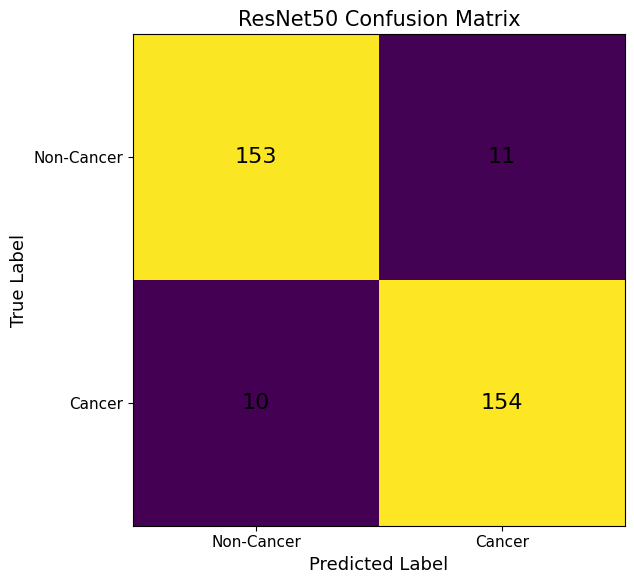

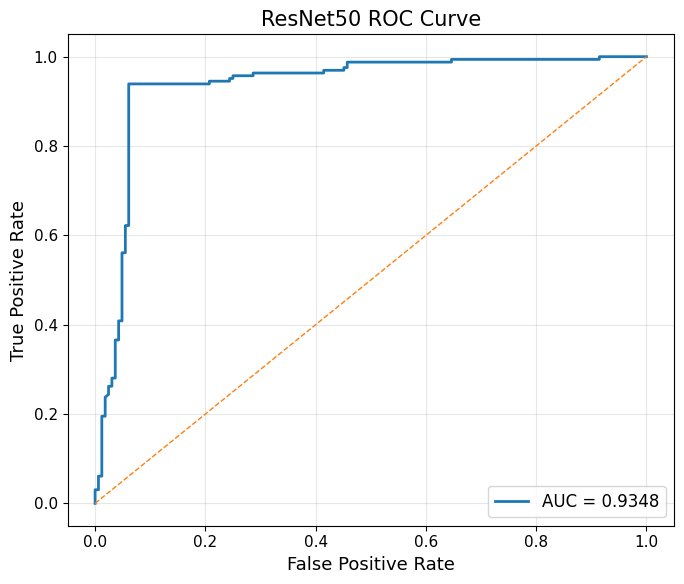

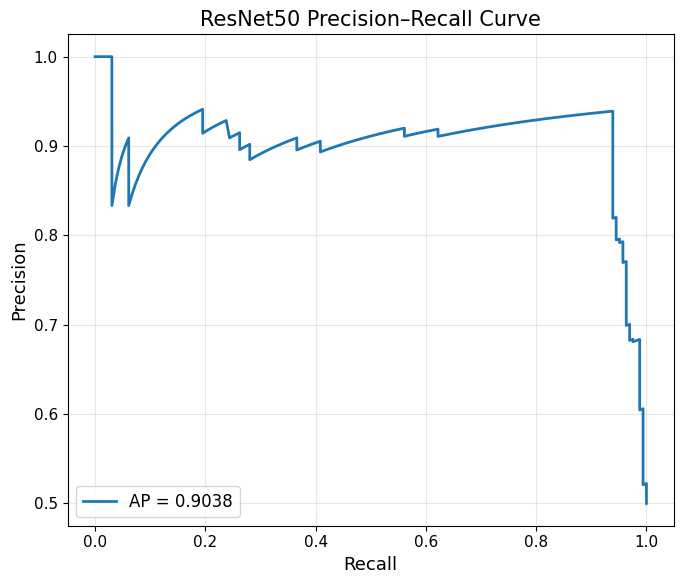

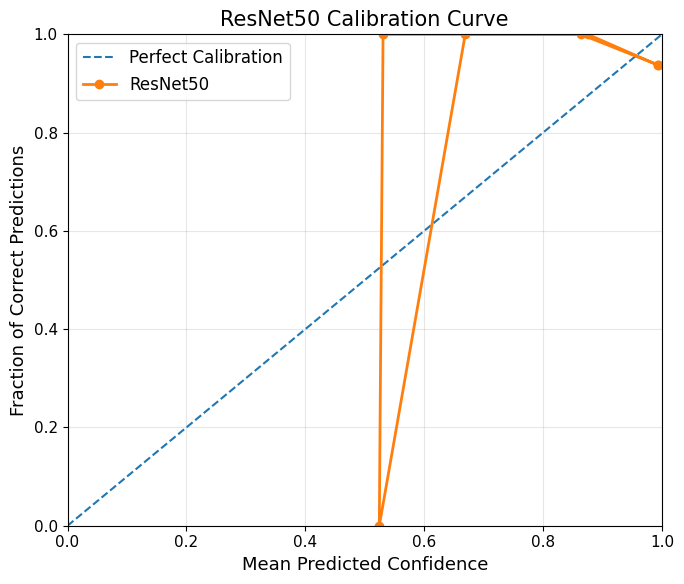

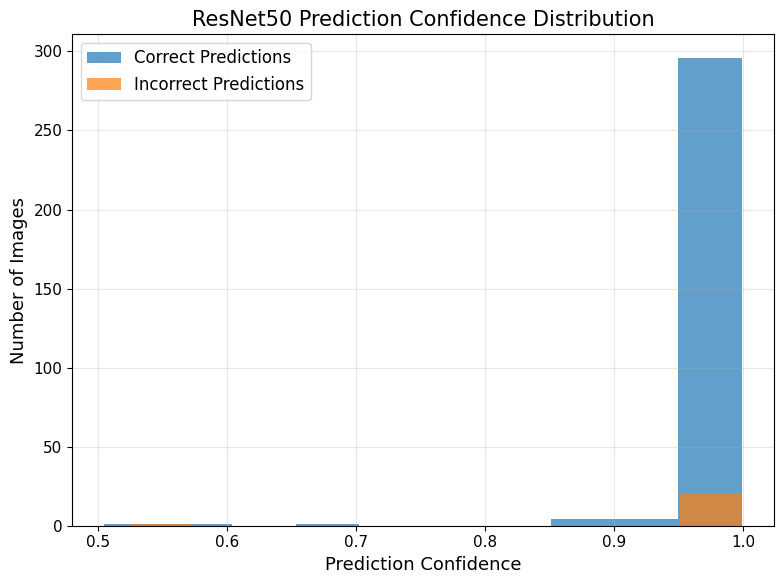

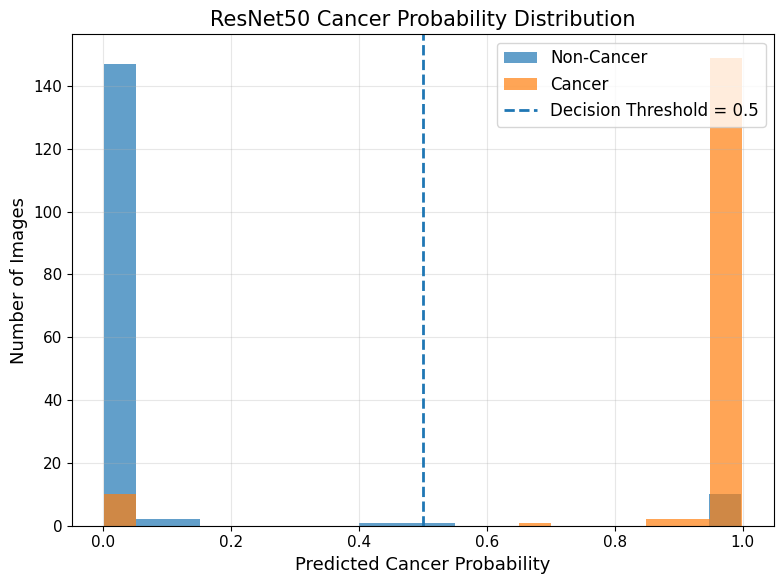

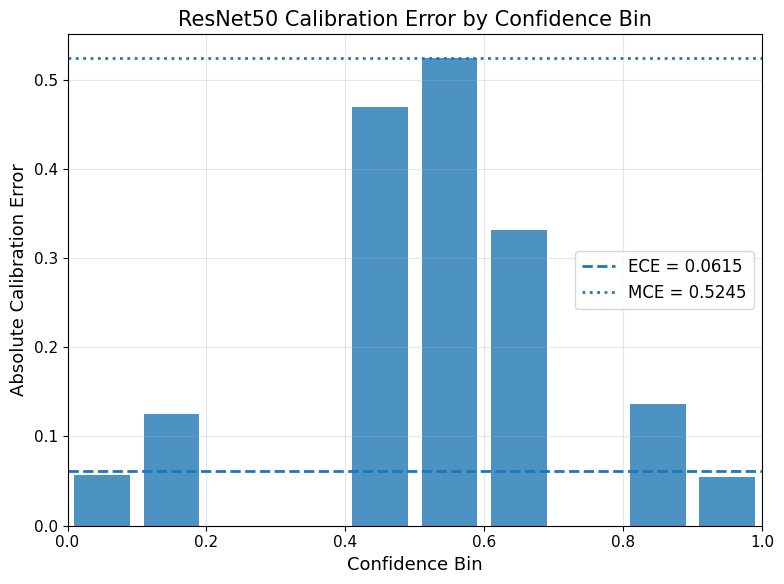

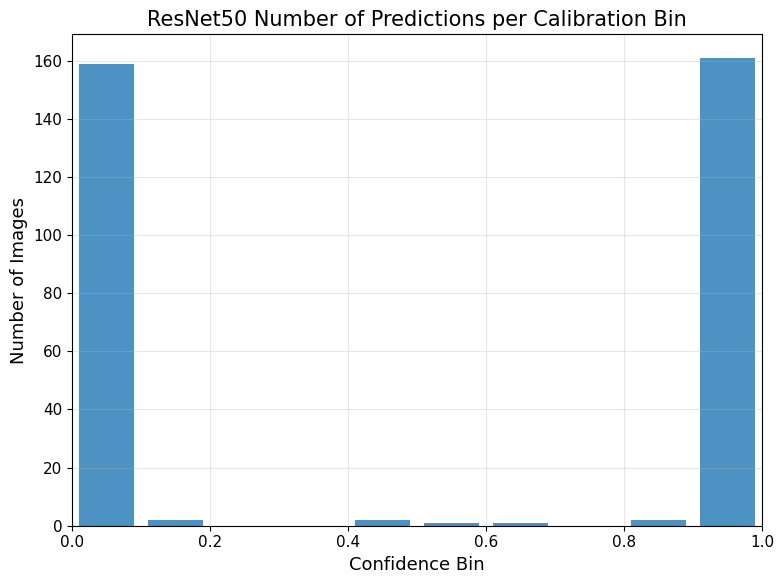



ALL RESNET50 PLOTS GENERATED

Saved files:
1. Confusion Matrix
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_confusion_matrix.png

2. ROC Curve
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_ROC_curve.png

3. Precision-Recall Curve
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_precision_recall_curve.png

4. Calibration Curve
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_calibration_curve.png

5. Confidence Histogram
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_confidence_histogram.png

6. Probability Distribution
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_probability_distribution.png

7. ECE/MCE Calibration Error
/content/drive/MyDrive/Classification/Results/ResNet50/Calibration_analysis/ResNet_epoch_50_ECE_MC

In [5]:
# ============================================================
# RESNET50 COMPLETE EVALUATION
# PERFORMANCE + CALIBRATION + CONFIDENCE INTERVALS + PLOTS
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision.models import resnet50, ResNet50_Weights
from torchvision.io import read_image
from torchvision import transforms

from tqdm import tqdm

# Optional sklearn metrics
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# ============================================================
# 2. PATHS
# ============================================================

weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/ResNet_50/"
    "epoch_50_weights.pth"
)

test_root = (
    "/content/drive/MyDrive/"
    "Classification/Bt_training_and_testing/"
    "Testing_resized_v2"
)

save_dir = (
    "/content/drive/MyDrive/"
    "Classification/Results/ResNet50/Calibration_analysis"
)

os.makedirs(save_dir, exist_ok=True)

print("\nModel weights:")
print(weights_path)

print("\nTest directory:")
print(test_root)

print("\nResults directory:")
print(save_dir)


# ============================================================
# 3. PREPROCESSING
# ============================================================

# SAME NORMALIZATION USED IN YOUR RESNET CODE

transform = transforms.Compose([
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 4. RESNET50 MODEL
# ============================================================

class ResNet50Binary(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V2
        )

        in_features = self.model.fc.in_features

        # Binary classifier produces ONE LOGIT
        self.model.fc = nn.Linear(
            in_features,
            1
        )

    def forward(self, x):
        return self.model(x)


# ============================================================
# 5. LOAD MODEL
# ============================================================

model = ResNet50Binary().to(device)

checkpoint = torch.load(
    weights_path,
    map_location=device
)

model.load_state_dict(
    checkpoint,
    strict=True
)

model.eval()

print("\n✅ ResNet50 model loaded successfully.")


# ============================================================
# 6. TEST CLASSES
# ============================================================

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}


# ============================================================
# 7. STORAGE
# ============================================================

TP = 0
FP = 0
TN = 0
FN = 0

accuracies = []

all_labels = []
all_probabilities = []
all_predictions = []
all_paths = []


# ============================================================
# 8. EVALUATION
# ============================================================

print("\n" + "=" * 70)
print("STARTING RESNET50 TEST EVALUATION")
print("=" * 70)

with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"\n⚠️ Folder does not exist: {folder}"
            )

            continue

        files = sorted(os.listdir(folder))

        for fname in tqdm(
            files,
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):
                continue

            path = os.path.join(
                folder,
                fname
            )

            try:

                # ------------------------------------------------
                # Read image
                # ------------------------------------------------

                image = read_image(path).float() / 255.0

                # ------------------------------------------------
                # Normalize
                # ------------------------------------------------

                image = transform(image)

                # ------------------------------------------------
                # Add batch dimension
                # ------------------------------------------------

                image = image.unsqueeze(0).to(device)

                # ------------------------------------------------
                # Forward pass
                # ------------------------------------------------

                logits = model(image)

                # ------------------------------------------------
                # Convert LOGIT -> probability
                # ------------------------------------------------

                probability = torch.sigmoid(
                    logits
                ).item()

                # ------------------------------------------------
                # Binary prediction
                # ------------------------------------------------

                pred = int(
                    probability >= 0.5
                )

                # ------------------------------------------------
                # Store
                # ------------------------------------------------

                all_labels.append(label)
                all_probabilities.append(probability)
                all_predictions.append(pred)
                all_paths.append(path)

                # Accuracy deviation
                accuracies.append(
                    int(pred == label)
                )

                # ------------------------------------------------
                # Confusion matrix
                # ------------------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1

            except Exception as e:

                print(
                    f"\n⚠️ Error processing {fname}: {e}"
                )

                continue


# ============================================================
# 9. CONVERT TO NUMPY
# ============================================================

all_labels = np.asarray(
    all_labels,
    dtype=int
)

all_probabilities = np.asarray(
    all_probabilities,
    dtype=float
)

all_predictions = np.asarray(
    all_predictions,
    dtype=int
)

accuracies = np.asarray(
    accuracies,
    dtype=int
)


# ============================================================
# 10. BASIC METRICS
# ============================================================

total = TP + FP + TN + FN

accuracy = (
    (TP + TN) / total
    if total
    else 0
)

sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)

specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)

precision = (
    TP / (TP + FP)
    if (TP + FP)
    else 0
)

f1_score = (
    2 * precision * sensitivity /
    (precision + sensitivity)
    if (precision + sensitivity)
    else 0
)

accuracy_std = (
    np.std(accuracies)
    if len(accuracies)
    else 0
)


# ============================================================
# 11. BRIER SCORE
# ============================================================

brier_score = np.mean(
    (all_probabilities - all_labels) ** 2
)


# ============================================================
# 12. ROC AUC
# ============================================================

if len(np.unique(all_labels)) == 2:

    roc_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

else:

    roc_auc = np.nan


# ============================================================
# 13. ECE + MCE
# ============================================================

def calculate_calibration_metrics(
    y_true,
    probabilities,
    n_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    bin_centers = []
    accuracies_bin = []
    confidences_bin = []
    counts_bin = []

    ece = 0.0
    mce = 0.0

    total_samples = len(y_true)

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (probabilities >= lower) &
                (probabilities <= upper)
            )

        else:

            mask = (
                (probabilities >= lower) &
                (probabilities < upper)
            )

        count = np.sum(mask)

        if count == 0:

            bin_centers.append(
                (lower + upper) / 2
            )

            accuracies_bin.append(
                np.nan
            )

            confidences_bin.append(
                np.nan
            )

            counts_bin.append(0)

            continue

        bin_accuracy = np.mean(
            y_true[mask] ==
            (probabilities[mask] >= 0.5)
        )

        # Mean confidence for a binary model:
        # confidence = probability of predicted class
        bin_confidence = np.mean(
            np.maximum(
                probabilities[mask],
                1 - probabilities[mask]
            )
        )

        error = abs(
            bin_accuracy -
            bin_confidence
        )

        weighted_error = (
            count / total_samples
        ) * error

        ece += weighted_error

        mce = max(
            mce,
            error
        )

        bin_centers.append(
            (lower + upper) / 2
        )

        accuracies_bin.append(
            bin_accuracy
        )

        confidences_bin.append(
            bin_confidence
        )

        counts_bin.append(
            count
        )

    return (
        ece,
        mce,
        np.asarray(bin_centers),
        np.asarray(accuracies_bin),
        np.asarray(confidences_bin),
        np.asarray(counts_bin)
    )


(
    ece,
    mce,
    bin_centers,
    calibration_accuracy,
    calibration_confidence,
    calibration_counts
) = calculate_calibration_metrics(
    all_labels,
    all_probabilities,
    n_bins=10
)


# ============================================================
# 14. 95% CONFIDENCE INTERVALS
# ============================================================

def wilson_ci(
    successes,
    n,
    confidence=0.95
):

    if n == 0:

        return np.nan, np.nan

    z = 1.959963984540054

    p = successes / n

    denominator = (
        1 + z**2 / n
    )

    center = (
        p + z**2 / (2 * n)
    ) / denominator

    margin = (
        z *
        np.sqrt(
            (
                p * (1 - p) / n
            )
            +
            (
                z**2 / (4 * n**2)
            )
        )
        / denominator
    )

    lower = max(
        0,
        center - margin
    )

    upper = min(
        1,
        center + margin
    )

    return lower, upper


# Accuracy CI
accuracy_ci_low, accuracy_ci_high = wilson_ci(
    TP + TN,
    total
)

# Sensitivity CI
sensitivity_ci_low, sensitivity_ci_high = wilson_ci(
    TP,
    TP + FN
)

# Specificity CI
specificity_ci_low, specificity_ci_high = wilson_ci(
    TN,
    TN + FP
)

# Precision CI
precision_ci_low, precision_ci_high = wilson_ci(
    TP,
    TP + FP
)


# ============================================================
# 15. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("RESNET50 PERFORMANCE RESULTS")
print("=" * 70)

print(f"Total Images       : {total}")

print("\nConfusion Matrix")
print("-" * 40)

print(f"TP                 : {TP}")
print(f"FP                 : {FP}")
print(f"TN                 : {TN}")
print(f"FN                 : {FN}")

print("\nPerformance Metrics")
print("-" * 40)

print(
    f"Accuracy           : "
    f"{accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Sensitivity        : "
    f"{sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"Specificity        : "
    f"{specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"Precision          : "
    f"{precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"F1-Score           : "
    f"{f1_score:.4f}"
)

print(
    f"Accuracy StdDev    : "
    f"{accuracy_std:.4f}"
)

print(
    f"ROC-AUC            : "
    f"{roc_auc:.4f}"
)

print("\nCalibration Metrics")
print("-" * 40)

print(
    f"ECE                : "
    f"{ece:.4f}"
)

print(
    f"MCE                : "
    f"{mce:.4f}"
)

print(
    f"Brier Score        : "
    f"{brier_score:.4f}"
)

print("\n95% Confidence Intervals")
print("-" * 40)

print(
    f"Accuracy           : "
    f"[{accuracy_ci_low:.4f}, "
    f"{accuracy_ci_high:.4f}]"
)

print(
    f"Sensitivity        : "
    f"[{sensitivity_ci_low:.4f}, "
    f"{sensitivity_ci_high:.4f}]"
)

print(
    f"Specificity        : "
    f"[{specificity_ci_low:.4f}, "
    f"{specificity_ci_high:.4f}]"
)

print(
    f"Precision          : "
    f"[{precision_ci_low:.4f}, "
    f"{precision_ci_high:.4f}]"
)

print("=" * 70)


# ============================================================
# 16. SAVE MAIN RESULTS CSV
# ============================================================

results = pd.DataFrame({

    "Model": [
        "ResNet50"
    ],

    "TP": [TP],
    "FP": [FP],
    "TN": [TN],
    "FN": [FN],

    "Total": [total],

    "Accuracy": [
        round(accuracy, 4)
    ],

    "Sensitivity": [
        round(sensitivity, 4)
    ],

    "Specificity": [
        round(specificity, 4)
    ],

    "Precision": [
        round(precision, 4)
    ],

    "F1-Score": [
        round(f1_score, 4)
    ],

    "Accuracy StdDev": [
        round(accuracy_std, 4)
    ],

    "ROC-AUC": [
        round(roc_auc, 4)
    ],

    "ECE": [
        round(ece, 4)
    ],

    "MCE": [
        round(mce, 4)
    ],

    "Brier Score": [
        round(brier_score, 4)
    ],

    "Accuracy CI Lower": [
        round(accuracy_ci_low, 4)
    ],

    "Accuracy CI Upper": [
        round(accuracy_ci_high, 4)
    ],

    "Sensitivity CI Lower": [
        round(sensitivity_ci_low, 4)
    ],

    "Sensitivity CI Upper": [
        round(sensitivity_ci_high, 4)
    ],

    "Specificity CI Lower": [
        round(specificity_ci_low, 4)
    ],

    "Specificity CI Upper": [
        round(specificity_ci_high, 4)
    ],

    "Precision CI Lower": [
        round(precision_ci_low, 4)
    ],

    "Precision CI Upper": [
        round(precision_ci_high, 4)
    ]
})


results_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_complete_metrics.csv"
)

results.to_csv(
    results_path,
    index=False
)

print(
    f"\n✅ Metrics saved to:\n{results_path}"
)


# ============================================================
# 17. SAVE DETAILED PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({

    "Image_Path": all_paths,

    "True_Label": all_labels,

    "Predicted_Label": all_predictions,

    "Cancer_Probability": all_probabilities,

    "Correct": (
        all_predictions ==
        all_labels
    ).astype(int)

})


prediction_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)

print(
    f"✅ Predictions saved to:\n{prediction_path}"
)


# ============================================================
# 18. PLOT STYLE
# ============================================================

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11
})


# ============================================================
# PLOT 1 — CONFUSION MATRIX
# ============================================================

cm = np.array([
    [TN, FP],
    [FN, TP]
])

fig, ax = plt.subplots(
    figsize=(7, 6)
)

im = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Non-Cancer",
    "Cancer"
])

ax.set_yticklabels([
    "Non-Cancer",
    "Cancer"
])

ax.set_xlabel(
    "Predicted Label"
)

ax.set_ylabel(
    "True Label"
)

ax.set_title(
    "ResNet50 Confusion Matrix"
)

for i in range(2):

    for j in range(2):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16
        )

plt.tight_layout()

cm_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOT 2 — ROC CURVE
# ============================================================

if len(np.unique(all_labels)) == 2:

    fpr, tpr, thresholds = roc_curve(
        all_labels,
        all_probabilities
    )

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"AUC = {roc_auc:.4f}"
    )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        "False Positive Rate"
    )

    ax.set_ylabel(
        "True Positive Rate"
    )

    ax.set_title(
        "ResNet50 ROC Curve"
    )

    ax.legend(
        loc="lower right"
    )

    ax.grid(
        alpha=0.3
    )

    plt.tight_layout()

    roc_path = os.path.join(
        save_dir,
        "ResNet_epoch_50_ROC_curve.png"
    )

    plt.savefig(
        roc_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# PLOT 3 — PRECISION-RECALL CURVE
# ============================================================

precision_values, recall_values, _ = precision_recall_curve(
    all_labels,
    all_probabilities
)

ap = average_precision_score(
    all_labels,
    all_probabilities
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ax.plot(
    recall_values,
    precision_values,
    linewidth=2,
    label=f"AP = {ap:.4f}"
)

ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_title(
    "ResNet50 Precision–Recall Curve"
)

ax.legend(
    loc="lower left"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

pr_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_precision_recall_curve.png"
)

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOT 4 — CALIBRATION / RELIABILITY CURVE
# ============================================================

valid_bins = ~np.isnan(
    calibration_accuracy
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect Calibration"
)

ax.plot(
    calibration_confidence[valid_bins],
    calibration_accuracy[valid_bins],
    marker="o",
    linewidth=2,
    label="ResNet50"
)

ax.set_xlabel(
    "Mean Predicted Confidence"
)

ax.set_ylabel(
    "Fraction of Correct Predictions"
)

ax.set_title(
    "ResNet50 Calibration Curve"
)

ax.legend()

ax.grid(
    alpha=0.3
)

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1
)

plt.tight_layout()

calibration_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_calibration_curve.png"
)

plt.savefig(
    calibration_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOT 5 — CONFIDENCE HISTOGRAM
# ============================================================

confidence = np.maximum(
    all_probabilities,
    1 - all_probabilities
)

correct_mask = (
    all_predictions ==
    all_labels
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.hist(
    confidence[correct_mask],
    bins=10,
    alpha=0.7,
    label="Correct Predictions"
)

ax.hist(
    confidence[~correct_mask],
    bins=10,
    alpha=0.7,
    label="Incorrect Predictions"
)

ax.set_xlabel(
    "Prediction Confidence"
)

ax.set_ylabel(
    "Number of Images"
)

ax.set_title(
    "ResNet50 Prediction Confidence Distribution"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

confidence_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_confidence_histogram.png"
)

plt.savefig(
    confidence_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOT 6 — CANCER PROBABILITY DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.hist(
    all_probabilities[all_labels == 0],
    bins=20,
    alpha=0.7,
    label="Non-Cancer"
)

ax.hist(
    all_probabilities[all_labels == 1],
    bins=20,
    alpha=0.7,
    label="Cancer"
)

ax.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Decision Threshold = 0.5"
)

ax.set_xlabel(
    "Predicted Cancer Probability"
)

ax.set_ylabel(
    "Number of Images"
)

ax.set_title(
    "ResNet50 Cancer Probability Distribution"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

probability_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_probability_distribution.png"
)

plt.savefig(
    probability_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOT 7 — ECE / MCE CALIBRATION BIN ERROR
# ============================================================

bin_errors = np.abs(
    calibration_accuracy -
    calibration_confidence
)

valid_error_bins = ~np.isnan(
    bin_errors
)

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.bar(
    bin_centers[valid_error_bins],
    bin_errors[valid_error_bins],
    width=0.08,
    alpha=0.8
)

ax.axhline(
    ece,
    linestyle="--",
    linewidth=2,
    label=f"ECE = {ece:.4f}"
)

ax.axhline(
    mce,
    linestyle=":",
    linewidth=2,
    label=f"MCE = {mce:.4f}"
)

ax.set_xlabel(
    "Confidence Bin"
)

ax.set_ylabel(
    "Absolute Calibration Error"
)

ax.set_title(
    "ResNet50 Calibration Error by Confidence Bin"
)

ax.set_xlim(
    0,
    1
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

ece_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_ECE_MCE_bins.png"
)

plt.savefig(
    ece_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# PLOT 8 — CALIBRATION BIN COUNTS
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.bar(
    bin_centers,
    calibration_counts,
    width=0.08,
    alpha=0.8
)

ax.set_xlabel(
    "Confidence Bin"
)

ax.set_ylabel(
    "Number of Images"
)

ax.set_title(
    "ResNet50 Number of Predictions per Calibration Bin"
)

ax.set_xlim(
    0,
    1
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

bin_count_path = os.path.join(
    save_dir,
    "ResNet_epoch_50_calibration_bin_counts.png"
)

plt.savefig(
    bin_count_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 19. SAVE CALIBRATION BIN DATA
# ============================================================

calibration_df = pd.DataFrame({

    "Bin_Center":
        bin_centers,

    "Calibration_Accuracy":
        calibration_accuracy,

    "Mean_Confidence":
        calibration_confidence,

    "Absolute_Calibration_Error":
        bin_errors,

    "Sample_Count":
        calibration_counts
})

calibration_csv = os.path.join(
    save_dir,
    "ResNet_epoch_50_calibration_bins.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)


# ============================================================
# 20. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("ALL RESNET50 PLOTS GENERATED")
print("=" * 70)

print("\nSaved files:")

print("1. Confusion Matrix")
print(cm_path)

print("\n2. ROC Curve")
print(roc_path)

print("\n3. Precision-Recall Curve")
print(pr_path)

print("\n4. Calibration Curve")
print(calibration_path)

print("\n5. Confidence Histogram")
print(confidence_path)

print("\n6. Probability Distribution")
print(probability_path)

print("\n7. ECE/MCE Calibration Error")
print(ece_path)

print("\n8. Calibration Bin Counts")
print(bin_count_path)

print("\n9. Complete Metrics CSV")
print(results_path)

print("\n10. Detailed Predictions CSV")
print(prediction_path)

print("\n11. Calibration Bin CSV")
print(calibration_csv)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)